# Ticket practice

Each section matches a chapter of Keith's tutorial. Watch the chapter, then do the ticket exercise here.

Data: `../data/tickets.csv` (synthetic).

In [1]:
import pandas as pd

tickets = pd.read_csv('data/tickets.csv')
tickets.head()

,ticket_id,created,resolved,category,priority,status,assignee,channel
0,1001,2026-08-28 09:05,2026-09-01 03:34,Password reset,Low,Closed,Priya,Phone
1,1002,2026-08-28 10:06,2026-08-30 21:41,Access request,Low,Closed,Priya,Email
2,1003,2026-08-29 17:20,2026-08-31 08:58,Access request,Medium,Closed,Alex,Portal
3,1004,2026-08-30 10:40,NaN,Laptop hardware,Low,In progress,Sam,Slack
4,1005,2026-08-30 11:23,2026-08-30 15:07,Password reset,Medium,Closed,Sam,Portal


## Intro to DataFrames  (3:58)

**Exercise:** Build a tiny DataFrame by hand with 3 made-up tickets (ticket_id, category, priority). Then look at `.index`, `.columns`, `.shape` and `.info()`.

**What I learned:** 

In [2]:
tickets.columns


Index(['ticket_id', 'created', 'resolved', 'category', 'priority', 'status',
       'assignee', 'channel'],
      dtype='str')

A dataframe is the main data stucture of the python pandas library. they are like tables with extra functionality to allow us to work with spreadsheets and other types of tables.

To see a list of columns we can enter tickets.columns

In [3]:
tickets.index

RangeIndex(start=0, stop=250, step=1)

tickets.index shows us the row labels and the output describes them in shorthand. start=0: the first row is labelled 0. Python counts from 0, not 1.
stop=250: the labels go up to, but not including, 250. So the last row is 249, which gives 250 rows in total, matching your 250 tickets.
step=1: each label goes up by 1.

In [4]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ticket_id  250 non-null    int64
 1   created    250 non-null    str  
 2   resolved   220 non-null    str  
 3   category   247 non-null    str  
 4   priority   250 non-null    str  
 5   status     250 non-null    str  
 6   assignee   245 non-null    str  
 7   channel    250 non-null    str  
dtypes: int64(1), str(7)
memory usage: 31.6 KB


tickets.info shows information about the dataframe like size, each column type, and how many blanks each column has. this can be used as a health check and one of the first things to run on a new dataset. RangeIndex shows the number of entries. Non-Null Count refers to how many cells have values and in our case anything under 250 means how many cells are blank. Dtype is the type of data like int64 and str. memory usage shows we have only used 31.6KB. 

Our Non-Null Count is already showing us important details: the resolved column is only 220 resolved dates are entered, meaning 30 tickets are left open. category shows 3 tickets were never categorised and assignee shows 5 tickets with nobody assigned, meaning a queue issue.

In [5]:
tickets.describe()

,ticket_id
count,250.000000
mean,1125.500000
std,72.312977
min,1001.000000
25%,1063.250000
50%,1125.500000
75%,1187.750000
max,1250.000000


describe() gives summary statistics for number columns but in our data it only shows the the column for ticket_id.

In [6]:
tickets["created"] = pd.to_datetime(tickets["created"])
tickets["resolved"] = pd.to_datetime(tickets["resolved"])
tickets["resolution_hours"] = (tickets["resolved"] - tickets["created"]).dt.total_seconds() / 3600

tickets["created"] = pd.to_datetime(tickets["created" reads the created column and converts each text value and into a real date-and-time that pandas can do maths with and replaces the old text column with the converted one.

tickets["resolved"] = pd.to_datetime(tickets["resolved"]) Identical, but for resolved. Blank cells for open tickets become NaT (“Not a Time”), the date version of NaN.

tickets["resolution_hours"] = (tickets["resolved"] - tickets["created"]).dt.total_seconds() / 3600 This one has four steps, read left to right inside the brackets:

1. tickets["resolved"] - tickets["created"] subtracts row by row, for all 250 tickets at once. Each result is a time gap, e.g. 3 days 18:29:00.

2. .dt.total_seconds() converts each gap into seconds: 3 days 18 h 29 min = 325,740 seconds. The .dt part means “use date/time tools on this column”.

3. / 3600 divides by the 3,600 seconds in an hour, giving 90.48 hours.

4. tickets["resolution_hours"] = ... stores the result as a new column. Since the name didn’t exist before, pandas creates it.

For open tickets, NaT - date gives a blank, so they get NaN. That’s why describe() counted 220, not 250.

In [7]:
tickets["resolution_hours"].describe()

count    220.000000
mean      32.166439
std       27.109550
min        0.683333
25%       11.041667
50%       25.600000
75%       39.870833
max      107.216667
Name: resolution_hours, dtype: float64

tickets["resolution_hours"].describe() is more helpful since it applies statistics to ticket time. Here we can see that only 220 tickets have been closed, leaving 30 open. The fastest fix was 0.68 hours. The median shows that the typical ticket took 25.6 hours and the mean (average) is 32.2 hours meaning that some very slowly processes tickets are skewing the average.

In [8]:
tickets.nunique()

ticket_id           250
created             248
resolved            220
category              9
priority              3
status                3
assignee              4
channel               5
resolution_hours    216
dtype: int64

nunique() counts how many different values each column has. Blanks arent counted. importantly it shows that there are no duplicated ticket IDs.

In [9]:
tickets.shape

(250, 9)

tickets.shape shows the size of our tables (rows, columns). Importantly it is the quickest way to count results after filtering.

## Loading files  (8:25)

**Exercise:** Load your tickets: `tickets = pd.read_csv("../data/tickets.csv")`. Check `.shape` and `.info()`. Which columns have blanks?

**What I learned:** 

## head / tail / sample  (13:42)

**Exercise:** Show the 5 oldest tickets (`head`), the 5 newest (`tail`) and 5 random ones (`sample`).

**What I learned:** 

In [10]:
tickets.head()

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333
3,1004,2026-08-30 10:40:00,NaT,Laptop hardware,Low,In progress,Sam,Slack,NaN
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333


.head() shows us the oldest tickets but by changing the value in the brackets we can see more entries.

In [11]:
tickets.tail()

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
245,1246,2026-10-26 09:56:00,2026-10-27 08:51:00,Password reset,Low,Closed,Alex,Email,22.916667
246,1247,2026-10-26 12:50:00,NaT,Password reset,Low,In progress,Alex,Slack,NaN
247,1248,2026-10-26 14:03:00,2026-10-27 06:15:00,Password reset,Medium,Closed,Alex,Slack,16.200000
248,1249,2026-10-27 09:45:00,NaT,Password reset,Medium,Open,Alex,Slack,NaN
249,1250,2026-10-27 10:26:00,NaT,Access request,Low,Open,Jordan,Portal,NaN


.tail() shows us the newest tickets but by changing the value in the brackets we can see more entries.

In [12]:
tickets["category"].value_counts()

category
Password reset      70
Access request      47
Wi-Fi / network     40
Software install    30
Laptop hardware     20
Email / calendar    18
Phishing report      8
Printer              7
VPN                  7
Name: count, dtype: int64

In [13]:
tickets.sample(5)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
3,1004,2026-08-30 10:40:00,NaT,Laptop hardware,Low,In progress,Sam,Slack,NaN
105,1106,2026-09-21 15:17:00,2026-09-21 16:20:00,Wi-Fi / network,High,Closed,Jordan,Phone,1.050000
164,1165,2026-10-06 14:51:00,2026-10-10 00:45:00,Laptop hardware,Low,Closed,Alex,Slack,81.900000
52,1053,2026-09-09 17:28:00,2026-09-13 18:57:00,Access request,Low,Closed,Jordan,Slack,97.483333
166,1167,2026-10-07 08:13:00,2026-10-08 14:48:00,Password reset,Medium,Closed,Alex,Slack,30.583333


.samples(5) gives us a random selection of entries and is better for viewing data when the newest and oldest entries are less relevant

## Setting values with loc / iloc  (19:20)

**Exercise:** On a copy (`practice = tickets.copy()`), assign an unassigned open ticket to "Sam" using `.loc`. Why use a copy?

**What I learned:** 

In [14]:
tickets.loc[0]

ticket_id                          1001
created             2026-08-28 09:05:00
resolved            2026-09-01 03:34:00
category                 Password reset
priority                            Low
status                           Closed
assignee                          Priya
channel                           Phone
resolution_hours              90.483333
Name: 0, dtype: object

loc[0] will return the first row of the dataframe, which is a pandas Series object. 

In [15]:
tickets.loc[tickets["status"] != "Closed", ["ticket_id", "priority", "category", "assignee"]]

,ticket_id,priority,category,assignee
3,1004,Low,Laptop hardware,Sam
6,1007,Medium,Password reset,Priya
17,1018,Medium,Access request,Alex
20,1021,Medium,VPN,Priya
32,1033,Low,Access request,Alex
35,1036,High,Software install,Priya
44,1045,High,Access request,Sam
46,1047,Low,Password reset,Sam
57,1058,Low,Password reset,Priya
64,1065,Medium,Software install,Alex


To use .loc to identify tickets that are still open we can do so by using the expression:
  To list open tickets with `.loc`:
  ```python
  tickets.loc[tickets["status"] != "Closed", ["ticket_id", "priority", "category", "assignee"]]
  #           └─────── which rows ─────────┘  └──────── which columns ─────────┘
  ```
The rows part is a True/False condition (status != "Closed"), and the columns part is a list of column names. It returns a new filtered table and doesn’t change tickets.

This expression quickly allows us to find the open tickets so that we can resolve those issues.

In [16]:
tickets.iloc[0:5, 0:3]

,ticket_id,created,resolved
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00
3,1004,2026-08-30 10:40:00,NaT
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00


.iloc allows us to grab (rows, columns) but only using index values

In [17]:
tickets.loc[tickets["ticket_id"] == 1004, "status"] = "Closed"
tickets.loc[tickets["ticket_id"] == 1004, "resolved"] = pd.Timestamp("2026-08-30 17:00")

If i wanted to update a value, for example, an open ticket like 1004 i could use loc isolate the row for the ticket and update the status to closed. Then update the time for the resolved column on that row.

In [18]:
tickets.loc[tickets["ticket_id"] == 1004]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,NaN


we can see here that our ticket has been closed successfully. However, resolution_hours has not been updated. lets rerun our previous expression to update.

In [19]:
tickets["resolution_hours"] = (tickets["resolved"] - tickets["created"]).dt.total_seconds() / 3600
tickets.loc[tickets["ticket_id"] == 1004, "resolution_hours"]

3    6.333333
Name: resolution_hours, dtype: float64

In [20]:
tickets.loc[tickets["ticket_id"] == 1004]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333


After updating resolution_hours we can see that this entry is complete.

## at / iat  (20:20)

**Exercise:** Get the priority of the ticket in row 0 with `.at`, and the same value with `.iat`.

**What I learned:** 

In [21]:
tickets.at[5, "status"]

'Closed'

.at is a more optimized way og getting specific value. Here i can find what the status is for row 5.

In [22]:
tickets.iat[5, 5]

'Closed'

Similarly i can find the same information with .iat but just by using index values.

## Columns and sorting  (21:11)

**Exercise:** Sort tickets newest first by `created`. Then sort by `priority`, then `created`.

**What I learned:** 

In [23]:
tickets.sort_values(by="priority").head(10)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
5,1006,2026-08-30 15:12:00,2026-08-30 22:05:00,Wi-Fi / network,High,Closed,Jordan,Portal,6.883333
23,1024,2026-09-03 16:23:00,2026-09-03 18:58:00,Wi-Fi / network,High,Closed,Priya,Portal,2.583333
35,1036,2026-09-06 13:45:00,NaT,Software install,High,In progress,Priya,Phone,NaN
41,1042,2026-09-08 10:19:00,2026-09-08 11:00:00,Phishing report,High,Closed,Sam,Email,0.683333
44,1045,2026-09-08 16:58:00,NaT,Access request,High,In progress,Sam,Phone,NaN
47,1048,2026-09-08 17:44:00,2026-09-09 00:50:00,Phishing report,High,Closed,Priya,Slack,7.100000
53,1054,2026-09-10 08:45:00,2026-09-10 10:48:00,Wi-Fi / network,High,Closed,Sam,Slack,2.050000
56,1057,2026-09-11 11:20:00,2026-09-11 15:51:00,Password reset,High,Closed,Alex,Email,4.516667
62,1063,2026-09-12 13:50:00,2026-09-12 14:37:00,Email / calendar,High,Closed,Priya,Portal,0.783333
66,1067,2026-09-13 10:34:00,2026-09-13 13:50:00,Password reset,High,Closed,Priya,Phone,3.266667


Using .sort_values allows me to select a column and and sort by priority. however, there is an unexpected outcome when i sort in descending order.

In [24]:
tickets.sort_values(by="priority", ascending=False).head(10)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333
6,1007,2026-08-30 16:19:00,NaT,Password reset,Medium,In progress,Priya,Portal,NaN
7,1008,2026-08-30 16:21:00,2026-08-31 20:01:00,Email / calendar,Medium,Closed,Sam,Portal,27.666667
9,1010,2026-08-31 09:20:00,2026-08-31 13:49:00,Wi-Fi / network,Medium,Closed,Priya,Walk-in,4.483333
13,1014,2026-09-02 08:38:00,2026-09-03 23:22:00,Software install,Medium,Closed,Sam,Portal,38.733333
15,1016,2026-09-02 08:57:00,2026-09-03 12:52:00,Wi-Fi / network,Medium,Closed,Alex,Walk-in,27.916667
16,1017,2026-09-02 08:58:00,2026-09-03 05:50:00,Email / calendar,Medium,Closed,Alex,Slack,20.866667
17,1018,2026-09-02 09:28:00,NaT,Access request,Medium,In progress,Alex,Portal,NaN
19,1020,2026-09-02 11:27:00,2026-09-02 22:07:00,Access request,Medium,Closed,Priya,Slack,10.666667


Reversing the order of the sorting led me to believe i would be able to see lowest priority tickets. This mistake is crucial to how pandas work. pandas dont understand the words they only order in alphabetical order, thats why Medium is displayed rather than Low. To get my expected outcome i will need to rank the prioriities then try again.

In [25]:
priority_order = {"High": 1, "Medium": 2, "Low": 3}
tickets.sort_values(by="priority", key=lambda col: col.map(priority_order), ascending=False).head(10)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333
72,1073,2026-09-14 14:54:00,2026-09-16 09:40:00,Wi-Fi / network,Low,Closed,Alex,Portal,42.766667
134,1135,2026-09-28 17:39:00,2026-09-30 09:18:00,Wi-Fi / network,Low,Closed,Alex,Slack,39.650000
133,1134,2026-09-28 14:52:00,2026-09-29 23:18:00,Password reset,Low,Closed,Sam,Slack,32.433333
131,1132,2026-09-28 08:43:00,NaT,Password reset,Low,In progress,Alex,Slack,NaN
127,1128,2026-09-27 13:35:00,2026-10-01 05:53:00,Software install,Low,Closed,Alex,Walk-in,88.300000
126,1127,2026-09-27 11:12:00,2026-09-29 15:59:00,NaN,Low,Closed,Sam,Slack,52.783333
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333
123,1124,2026-09-26 17:56:00,2026-09-29 21:13:00,Password reset,Low,Closed,Alex,Slack,75.283333
122,1123,2026-09-26 12:32:00,2026-09-28 12:34:00,Wi-Fi / network,Low,Closed,Priya,Slack,48.033333


Here is a new expression to sort for the the lowest priority, the basic idea behind it to swap each priority word for a number, sort by the numbers, but still show the original words. 
step 1. priority_order = {"High": 1, "Medium": 2, "Low": 3}
makes a dictionary for each priority to correspond to a number.
Step 2. tickets["priority"].map(priority_order).head()
.map() swaps words for numbers
Step 3. lambda col: col.map(priority_order)
key= says: “before sorting, pass the column through this function, and sort by what comes out.”, lambda is a mini-function.

## Iterating with iterrows  (23:01)

**Exercise:** Loop over the first 5 tickets and print lines like `Ticket 1001: Password reset (Low)`. Note: loops are slow in pandas; filtering is usually better.

**What I learned:** 

In [26]:
for index, row in tickets.iterrows():
    print(index)
    print (row["ticket_id"], row["status"], row["priority"])
    print("\n\n")

0
1001 Closed Low



1
1002 Closed Low



2
1003 Closed Medium



3
1004 Closed Low



4
1005 Closed Medium



5
1006 Closed High



6
1007 In progress Medium



7
1008 Closed Medium



8
1009 Closed Low



9
1010 Closed Medium



10
1011 Closed Low



11
1012 Closed Low



12
1013 Closed Low



13
1014 Closed Medium



14
1015 Closed Low



15
1016 Closed Medium



16
1017 Closed Medium



17
1018 In progress Medium



18
1019 Closed Low



19
1020 Closed Medium



20
1021 In progress Medium



21
1022 Closed Medium



22
1023 Closed Low



23
1024 Closed High



24
1025 Closed Low



25
1026 Closed Low



26
1027 Closed Low



27
1028 Closed Medium



28
1029 Closed Low



29
1030 Closed Medium



30
1031 Closed Low



31
1032 Closed Medium



32
1033 Open Low



33
1034 Closed Medium



34
1035 Closed Low



35
1036 In progress High



36
1037 Closed Low



37
1038 Closed Low



38
1039 Closed Low



39
1040 Closed Low



40
1041 Closed Low



41
1042 Closed High



42
1043 Closed L

iterrows() allows us to go through the table one row at time.

In [27]:
unassigned = tickets.loc[(tickets["status"] != "Closed") & (tickets["assignee"].isna())]

for index, row in unassigned.iterrows():
    print(f"Ticket {row['ticket_id']} ({row['priority']}) has no owner. Please assign.")

Ticket 1101 (Medium) has no owner. Please assign.
Ticket 1188 (Low) has no owner. Please assign.
Ticket 1225 (Medium) has no owner. Please assign.
Ticket 1243 (Medium) has no owner. Please assign.
Ticket 1245 (Medium) has no owner. Please assign.


Find unassigned open tickets. A boolean mask keeps tickets that are not Closed (Open or In progress) and have no assignee. The result is stored as unassigned. No column list is given, so all columns are kept. The loop then prints a follow-up message for each ticket.

In [28]:
for index, row in unassigned.iterrows():
    print(f"Ticket {row['ticket_id']} has no owner.")

Ticket 1101 has no owner.
Ticket 1188 has no owner.
Ticket 1225 has no owner.
Ticket 1243 has no owner.
Ticket 1245 has no owner.


Important note: this is not the most efficient use for pandas since over a much larger data set than ours it can be much slower.

## Filtering  (24:12)

**Exercise:** Find: (a) open tickets (status not Closed), (b) open AND High priority, (c) open tickets with no assignee (`.isna()`). How many of each?

**What I learned:** 

In [29]:
tickets.loc[tickets["resolution_hours"] > 24]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333
7,1008,2026-08-30 16:21:00,2026-08-31 20:01:00,Email / calendar,Medium,Closed,Sam,Portal,27.666667
8,1009,2026-08-30 16:41:00,2026-09-02 04:13:00,Email / calendar,Low,Closed,Alex,Slack,59.533333
...,...,...,...,...,...,...,...,...,...
231,1232,2026-10-24 13:53:00,2026-10-25 16:22:00,Software install,Medium,Closed,Alex,Portal,26.483333
233,1234,2026-10-24 16:26:00,2026-10-27 07:30:00,Password reset,Low,Closed,Alex,Phone,63.066667
238,1239,2026-10-25 12:50:00,2026-10-26 12:51:00,Access request,Medium,Closed,Alex,Slack,24.016667
239,1240,2026-10-25 13:13:00,2026-10-27 03:20:00,Software install,Medium,Closed,Alex,Walk-in,38.116667


here we can find any tickets that are taking longer than 24 hours

In [30]:
tickets.loc[(tickets["resolution_hours"] > 24) & (tickets["status"] != "Closed")]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours


Here i wanted find tickets over 24 hours and tickets not resloved yet but my problem arises from "resolution_hours" only accounting for tickets with a resolved entry. 

In [31]:
now = pd.Timestamp.now()
tickets["age_hours"] = (now - tickets["created"]).dt.total_seconds() / 3600
tickets.loc[(tickets["age_hours"] > 24) & (tickets["status"] != "Closed")]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
6,1007,2026-08-30 16:19:00,NaT,Password reset,Medium,In progress,Priya,Portal,NaN,1531.258722
17,1018,2026-09-02 09:28:00,NaT,Access request,Medium,In progress,Alex,Portal,NaN,1466.108722
20,1021,2026-09-03 13:05:00,NaT,VPN,Medium,In progress,Priya,Email,NaN,1438.492055
32,1033,2026-09-06 10:07:00,NaT,Access request,Low,Open,Alex,Slack,NaN,1369.458722
35,1036,2026-09-06 13:45:00,NaT,Software install,High,In progress,Priya,Phone,NaN,1365.825389
44,1045,2026-09-08 16:58:00,NaT,Access request,High,In progress,Sam,Phone,NaN,1314.608722
46,1047,2026-09-08 17:18:00,NaT,Password reset,Low,Open,Sam,Slack,NaN,1314.275389
57,1058,2026-09-11 12:32:00,NaT,Password reset,Low,In progress,Priya,Slack,NaN,1247.042055
64,1065,2026-09-12 15:09:00,NaT,Software install,Medium,Open,Alex,Email,NaN,1220.425389
80,1081,2026-09-15 14:52:00,NaT,Access request,Low,In progress,Jordan,Walk-in,NaN,1148.708722


By making a new assignment of now by giving it the current timestamp i can substract the created entries from now and store the result to "age_hours". Now we can find unresloved tickets and how long theyve been open. However, i still want a complete table of unresolved tickets and tickets over 24 hours

In [32]:
problem_tickets = tickets.loc[
    (tickets["status"] != "Closed") | (tickets["resolution_hours"] > 24)
]
problem_tickets

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055
6,1007,2026-08-30 16:19:00,NaT,Password reset,Medium,In progress,Priya,Portal,NaN,1531.258722
7,1008,2026-08-30 16:21:00,2026-08-31 20:01:00,Email / calendar,Medium,Closed,Sam,Portal,27.666667,1531.225389
...,...,...,...,...,...,...,...,...,...,...
243,1244,2026-10-26 09:22:00,2026-10-27 10:02:00,Password reset,Medium,Closed,Jordan,Email,24.666667,170.208722
244,1245,2026-10-26 09:41:00,NaT,Access request,Medium,Open,NaN,Slack,NaN,169.892055
246,1247,2026-10-26 12:50:00,NaT,Password reset,Low,In progress,Alex,Slack,NaN,166.742055
248,1249,2026-10-27 09:45:00,NaT,Password reset,Medium,Open,Alex,Slack,NaN,145.825389


## Filtering with strings and regex  (27:58)

**Exercise:** Find categories containing "access" (ignore case). Then find network-type tickets with the regex `"Wi-Fi|VPN"`.

**What I learned:** 

In [33]:
tickets[tickets["assignee"].str.contains("Alex")]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055
8,1009,2026-08-30 16:41:00,2026-09-02 04:13:00,Email / calendar,Low,Closed,Alex,Slack,59.533333,1530.892055
11,1012,2026-08-31 14:34:00,2026-09-03 04:27:00,Password reset,Low,Closed,Alex,Slack,61.883333,1509.008722
14,1015,2026-09-02 08:48:00,2026-09-05 14:48:00,Phishing report,Low,Closed,Alex,Slack,78.000000,1466.775389
15,1016,2026-09-02 08:57:00,2026-09-03 12:52:00,Wi-Fi / network,Medium,Closed,Alex,Walk-in,27.916667,1466.625389
...,...,...,...,...,...,...,...,...,...,...
239,1240,2026-10-25 13:13:00,2026-10-27 03:20:00,Software install,Medium,Closed,Alex,Walk-in,38.116667,190.358722
245,1246,2026-10-26 09:56:00,2026-10-27 08:51:00,Password reset,Low,Closed,Alex,Email,22.916667,169.642055
246,1247,2026-10-26 12:50:00,NaT,Password reset,Low,In progress,Alex,Slack,NaN,166.742055
247,1248,2026-10-26 14:03:00,2026-10-27 06:15:00,Password reset,Medium,Closed,Alex,Slack,16.200000,165.525389


Here i can filter by assignee "Alex" by using .str.contains("Alex") to find any tickets created by alex

In [34]:
tickets.loc[tickets["category"].str.contains("Wi-Fi|VPN", na=False)]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
5,1006,2026-08-30 15:12:00,2026-08-30 22:05:00,Wi-Fi / network,High,Closed,Jordan,Portal,6.883333,1532.375389
9,1010,2026-08-31 09:20:00,2026-08-31 13:49:00,Wi-Fi / network,Medium,Closed,Priya,Walk-in,4.483333,1514.242055
15,1016,2026-09-02 08:57:00,2026-09-03 12:52:00,Wi-Fi / network,Medium,Closed,Alex,Walk-in,27.916667,1466.625389
20,1021,2026-09-03 13:05:00,NaT,VPN,Medium,In progress,Priya,Email,NaN,1438.492055
22,1023,2026-09-03 13:54:00,2026-09-06 02:27:00,VPN,Low,Closed,Priya,Portal,60.550000,1437.675389
23,1024,2026-09-03 16:23:00,2026-09-03 18:58:00,Wi-Fi / network,High,Closed,Priya,Portal,2.583333,1435.192055
25,1026,2026-09-04 08:14:00,2026-09-08 01:34:00,VPN,Low,Closed,Alex,Email,89.333333,1419.342055
29,1030,2026-09-05 10:34:00,2026-09-05 16:27:00,Wi-Fi / network,Medium,Closed,Alex,Slack,5.883333,1393.008722
33,1034,2026-09-06 10:46:00,2026-09-07 04:22:00,Wi-Fi / network,Medium,Closed,Alex,Email,17.600000,1368.808722
37,1038,2026-09-07 08:28:00,2026-09-10 01:03:00,Wi-Fi / network,Low,Closed,Priya,Portal,64.583333,1347.108722


Using regex (regular expressions), we can descibe text patterns like "Wifi" or "VPN" and show them in a table using loc()

In [35]:
tickets.loc[tickets["category"].str.contains("request$", na=False)]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055
10,1011,2026-08-31 10:47:00,2026-09-02 14:29:00,Access request,Low,Closed,Sam,Portal,51.700000,1512.792055
12,1013,2026-09-01 08:20:00,2026-09-03 18:57:00,Access request,Low,Closed,Priya,Slack,58.616667,1491.242055
17,1018,2026-09-02 09:28:00,NaT,Access request,Medium,In progress,Alex,Portal,NaN,1466.108722
19,1020,2026-09-02 11:27:00,2026-09-02 22:07:00,Access request,Medium,Closed,Priya,Slack,10.666667,1464.125389
30,1031,2026-09-05 13:49:00,2026-09-07 00:36:00,Access request,Low,Closed,Sam,Slack,34.783333,1389.758722
32,1033,2026-09-06 10:07:00,NaT,Access request,Low,Open,Alex,Slack,NaN,1369.458722
38,1039,2026-09-07 12:36:00,2026-09-08 13:04:00,Access request,Low,Closed,Priya,Slack,24.466667,1342.975389
44,1045,2026-09-08 16:58:00,NaT,Access request,High,In progress,Sam,Phone,NaN,1314.608722


Using regex (regular expressions), we can descibe text patterns like "request" and find categories ending in it by using $

In [36]:
tickets.loc[tickets["category"].str.contains("access", case=False, na=False)]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055
10,1011,2026-08-31 10:47:00,2026-09-02 14:29:00,Access request,Low,Closed,Sam,Portal,51.700000,1512.792055
12,1013,2026-09-01 08:20:00,2026-09-03 18:57:00,Access request,Low,Closed,Priya,Slack,58.616667,1491.242055
17,1018,2026-09-02 09:28:00,NaT,Access request,Medium,In progress,Alex,Portal,NaN,1466.108722
19,1020,2026-09-02 11:27:00,2026-09-02 22:07:00,Access request,Medium,Closed,Priya,Slack,10.666667,1464.125389
30,1031,2026-09-05 13:49:00,2026-09-07 00:36:00,Access request,Low,Closed,Sam,Slack,34.783333,1389.758722
32,1033,2026-09-06 10:07:00,NaT,Access request,Low,Open,Alex,Slack,NaN,1369.458722
38,1039,2026-09-07 12:36:00,2026-09-08 13:04:00,Access request,Low,Closed,Priya,Slack,24.466667,1342.975389
44,1045,2026-09-08 16:58:00,NaT,Access request,High,In progress,Sam,Phone,NaN,1314.608722


Filtering with str.contains("access", case=False, na=False)] ignores upper and lower case. This may be important in case that this category was mislabled slightly

In [37]:
tickets[tickets["category"].isin(["Wi-Fi / network", "VPN"]) & (tickets["status"] != "Closed")]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
20,1021,2026-09-03 13:05:00,NaT,VPN,Medium,In progress,Priya,Email,NaN,1438.492055
128,1129,2026-09-27 15:01:00,NaT,Wi-Fi / network,High,In progress,Alex,Slack,NaN,860.558722
224,1225,2026-10-22 08:19:00,NaT,Wi-Fi / network,Medium,Open,NaN,Slack,NaN,267.258722


Here we can use .isin to find issues relating to just wifi and VPN that are still unresolved but importantly .isin only works with exact names unlike .str.contains() which can match just part of the text

## Query  (33:09)

**Exercise:** Rewrite filter (b) using `tickets.query(...)`. Which style do you find easier to read?

**What I learned:** 

In [38]:
tickets.query('channel == "Email" and priority == "Medium"')

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
20,1021,2026-09-03 13:05:00,NaT,VPN,Medium,In progress,Priya,Email,NaN,1438.492055
33,1034,2026-09-06 10:46:00,2026-09-07 04:22:00,Wi-Fi / network,Medium,Closed,Alex,Email,17.600000,1368.808722
63,1064,2026-09-12 14:31:00,2026-09-12 22:07:00,Email / calendar,Medium,Closed,Jordan,Email,7.600000,1221.058722
64,1065,2026-09-12 15:09:00,NaT,Software install,Medium,Open,Alex,Email,NaN,1220.425389
68,1069,2026-09-13 15:40:00,2026-09-13 22:47:00,Password reset,Medium,Closed,Jordan,Email,7.116667,1195.908722
83,1084,2026-09-16 08:05:00,2026-09-17 00:24:00,Laptop hardware,Medium,Closed,Priya,Email,16.316667,1131.492055
93,1094,2026-09-18 13:36:00,2026-09-18 18:14:00,Printer,Medium,Closed,Sam,Email,4.633333,1077.975389
108,1109,2026-09-22 10:59:00,2026-09-23 22:27:00,Software install,Medium,Closed,Alex,Email,35.466667,984.592055
113,1114,2026-09-23 13:19:00,2026-09-24 10:48:00,Printer,Medium,Closed,Alex,Email,21.483333,958.258722
115,1116,2026-09-24 08:42:00,2026-09-25 15:49:00,Password reset,Medium,Closed,Alex,Email,31.116667,938.875389


We can use the .query method to find useful info like which medium priority tickets are submitted by email.

## Adding / removing columns  (34:20)

**Exercise:** Add an `is_open` True/False column. Rename `assignee` to `owner` on a copy, then drop a column you don't need.

**What I learned:** 

In [39]:
tickets.head()

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333,1536.908722
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,1536.192055


In [40]:
tickets["team"] = "IT Support"

## Strings and datetimes  (41:40)

**Exercise:** Convert `created` and `resolved` with `pd.to_datetime`. Add `resolution_hours` for closed tickets and `age_days` for open ones. Add the weekday each ticket was created.

**What I learned:** 

In [41]:
import numpy as np
tickets["urgent"] = np.where(tickets["priority"] == "High", "Yes", "No")

In [42]:
tickets.head(5)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055,IT Support,No
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389,IT Support,No
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055,IT Support,No
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333,1536.908722,IT Support,No
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,1536.192055,IT Support,No


In [43]:
tickets["state"] = np.where(tickets["status"] == "Closed", "Resolved", "Unresolved")

Here weve made a new column called state that maps status closed with resolved (TRUE) and if status is not closed (open or in progress) then state becomes unresolved (FALSE). This could more easily highlight what tickets need attending to.

In [44]:
tickets.query('priority in ["High", "Medium"]')

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055,IT Support,No,Resolved
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,1536.192055,IT Support,No,Resolved
5,1006,2026-08-30 15:12:00,2026-08-30 22:05:00,Wi-Fi / network,High,Closed,Jordan,Portal,6.883333,1532.375389,IT Support,Yes,Resolved
6,1007,2026-08-30 16:19:00,NaT,Password reset,Medium,In progress,Priya,Portal,NaN,1531.258722,IT Support,No,Unresolved
7,1008,2026-08-30 16:21:00,2026-08-31 20:01:00,Email / calendar,Medium,Closed,Sam,Portal,27.666667,1531.225389,IT Support,No,Resolved
...,...,...,...,...,...,...,...,...,...,...,...,...,...
242,1243,2026-10-26 08:50:00,NaT,Laptop hardware,Medium,Open,NaN,Slack,NaN,170.742055,IT Support,No,Unresolved
243,1244,2026-10-26 09:22:00,2026-10-27 10:02:00,Password reset,Medium,Closed,Jordan,Email,24.666667,170.208722,IT Support,No,Resolved
244,1245,2026-10-26 09:41:00,NaT,Access request,Medium,Open,NaN,Slack,NaN,169.892055,IT Support,No,Unresolved
247,1248,2026-10-26 14:03:00,2026-10-27 06:15:00,Password reset,Medium,Closed,Alex,Slack,16.200000,165.525389,IT Support,No,Resolved


Here i have tried to query only High and Medium priority but this isnt a great sample since i cant see any states that are High or Medium. The next instruction shows me a random sample of 10 that shows both states as well as priority.

In [45]:
tickets.query('priority in ["High", "Medium"]').sample(10)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state
90,1091,2026-09-17 16:17:00,2026-09-17 19:03:00,Password reset,High,Closed,Priya,Slack,2.766667,1099.292055,IT Support,Yes,Resolved
132,1133,2026-09-28 12:44:00,2026-09-29 01:04:00,Software install,Medium,Closed,Priya,Email,12.333333,838.842055,IT Support,No,Resolved
62,1063,2026-09-12 13:50:00,2026-09-12 14:37:00,Email / calendar,High,Closed,Priya,Portal,0.783333,1221.742055,IT Support,Yes,Resolved
180,1181,2026-10-11 08:41:00,2026-10-12 00:47:00,Wi-Fi / network,Medium,Closed,Sam,Slack,16.100000,530.892055,IT Support,No,Resolved
220,1221,2026-10-20 16:32:00,2026-10-22 00:01:00,Software install,Medium,Closed,Jordan,Slack,31.483333,307.042055,IT Support,No,Resolved
219,1220,2026-10-20 15:58:00,2026-10-21 16:56:00,Wi-Fi / network,Medium,Closed,Jordan,Slack,24.966667,307.608722,IT Support,No,Resolved
115,1116,2026-09-24 08:42:00,2026-09-25 15:49:00,Password reset,Medium,Closed,Alex,Email,31.116667,938.875389,IT Support,No,Resolved
142,1143,2026-09-30 17:25:00,2026-10-02 09:18:00,Laptop hardware,Medium,Closed,Priya,Slack,39.883333,786.158722,IT Support,No,Resolved
206,1207,2026-10-17 14:38:00,2026-10-17 17:59:00,Printer,High,Closed,Priya,Slack,3.350000,380.942055,IT Support,Yes,Resolved
17,1018,2026-09-02 09:28:00,NaT,Access request,Medium,In progress,Alex,Portal,NaN,1466.108722,IT Support,No,Unresolved


In [46]:
tickets["weekday"] = tickets["created"].dt.day_name()
tickets[["ticket_id", "created", "weekday"]].head()

,ticket_id,created,weekday
0,1001,2026-08-28 09:05:00,Friday
1,1002,2026-08-28 10:06:00,Friday
2,1003,2026-08-29 17:20:00,Saturday
3,1004,2026-08-30 10:40:00,Sunday
4,1005,2026-08-30 11:23:00,Sunday


By applying .dt.day_name() to "created" i can create new column called weekday that will show what day of the week a ticket was made but its not very useful without seeing how many tickets a day there are.

In [47]:
tickets["weekday"].value_counts()

weekday
Monday       47
Sunday       39
Tuesday      39
Saturday     36
Wednesday    33
Friday       31
Thursday     25
Name: count, dtype: int64

Here i can see the busiest day was monday but the data are mixed up. Id rather view the days in order.

In [48]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
tickets["weekday"].value_counts().reindex(days)

weekday
Monday       47
Tuesday      39
Wednesday    33
Thursday     25
Friday       31
Saturday     36
Sunday       39
Name: count, dtype: int64

Using reindex(days) will rearrange the days in calendar order according to the list i gave it and in the order i gave them.

## Saving  (46:38)

**Exercise:** Save the open tickets to `../output/open_tickets.csv`. Open the file to check it.

**What I learned:** 

In [49]:
tickets.to_csv("output/tickets_enriched.csv", index=False)

This is just an example how to save the columns weve made so far. Its important not to overwrite the original tickets.csv. In future id like to save more specific outputs for unresolved tickets or tickets per assignee.

## apply and lambda  (47:14)

**Exercise:** Write a function that returns an SLA target in hours from a priority (High 4, Medium 24, Low 72) and use `.apply` to add an `sla_hours` column.

**What I learned:** 

.apply() runs your own function on every row, then collects the results. Here we can attempt find how many tickets have been met according to service level agreement (SLA).

In [50]:
def sla_target(priority):
    if priority == "High":
        return 4
    elif priority == "Medium":
        return 24
    else:
        return 72

Here we are using if/elif/else loops to define each priority with the expected time it takes to resolve. For example, High priority equals 4 hours, Medium equals 24, etc.

In [51]:
sla_target("High")

4

Quick test to see that was successful.

In [52]:
tickets["sla_hours_apply"] = tickets["priority"].apply(sla_target)

Here use .apply() sla_target to the whole column. The pandas passes each priority, one at a time, into sla_target and stores the 250 answers as a new column.

In [53]:
tickets.sample(5)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply
231,1232,2026-10-24 13:53:00,2026-10-25 16:22:00,Software install,Medium,Closed,Alex,Portal,26.483333,213.692055,IT Support,No,Resolved,Saturday,24
154,1155,2026-10-05 08:06:00,2026-10-06 17:58:00,Phishing report,Medium,Closed,Sam,Email,33.866667,675.475389,IT Support,No,Resolved,Monday,24
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055,IT Support,No,Resolved,Friday,72
211,1212,2026-10-18 12:52:00,2026-10-18 13:48:00,Email / calendar,High,Closed,Priya,Portal,0.933333,358.708722,IT Support,Yes,Resolved,Sunday,4
39,1040,2026-09-07 17:14:00,2026-09-09 13:33:00,Software install,Low,Closed,Alex,Portal,44.316667,1338.342055,IT Support,No,Resolved,Monday,72


In [54]:
def sla_status(row):
    if row["status"] != "Closed":
        return "Open"
    elif row["resolution_hours"] > row["sla_hours_apply"]:
        return "Breached"
    else:
        return "Met"

tickets["sla_status"] = tickets.apply(sla_status, axis=1)
    

In [55]:
tickets["sla_hours_apply"].unique()

array([72, 24,  4])

Here we can define a new column with a function applied to each row that says if a status cell is anything but closed, it should return "Open". elif says that if a cell for resolution_hours is over its sla_hours then it should return "breached". And else will return closed tickets as "Met" that were resolved within the service level agreement because they dont meet any of the requirements.

In [56]:
tickets["sla_status"].value_counts()

sla_status
Met         130
Breached     91
Open         29
Name: count, dtype: int64

Here we have a report of tickets that have met SLA and those that have breached.

In [57]:
tickets.sample(10)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply,sla_status
218,1219,2026-10-20 09:30:00,2026-10-21 01:15:00,Password reset,Medium,Closed,Priya,Email,15.750000,314.075389,IT Support,No,Resolved,Tuesday,24,Met
64,1065,2026-09-12 15:09:00,NaT,Software install,Medium,Open,Alex,Email,NaN,1220.425389,IT Support,No,Unresolved,Saturday,24,Open
21,1022,2026-09-03 13:42:00,2026-09-03 18:10:00,Email / calendar,Medium,Closed,Jordan,Phone,4.466667,1437.875389,IT Support,No,Resolved,Thursday,24,Met
204,1205,2026-10-17 12:28:00,2026-10-18 08:05:00,Password reset,Low,Closed,Jordan,Slack,19.616667,383.108722,IT Support,No,Resolved,Saturday,72,Met
136,1137,2026-09-29 11:34:00,2026-10-01 02:15:00,Password reset,Medium,Closed,Jordan,Portal,38.683333,816.008722,IT Support,No,Resolved,Tuesday,24,Breached
198,1199,2026-10-16 08:53:00,2026-10-17 05:42:00,Phishing report,Medium,Closed,Jordan,Slack,20.816667,410.692055,IT Support,No,Resolved,Friday,24,Met
216,1217,2026-10-19 16:56:00,2026-10-22 05:12:00,Access request,Low,Closed,Sam,Portal,60.266667,330.642055,IT Support,No,Resolved,Monday,72,Met
191,1192,2026-10-14 13:38:00,2026-10-14 20:35:00,Access request,High,Closed,Jordan,Email,6.950000,453.942055,IT Support,Yes,Resolved,Wednesday,4,Breached
52,1053,2026-09-09 17:28:00,2026-09-13 18:57:00,Access request,Low,Closed,Jordan,Slack,97.483333,1290.108722,IT Support,No,Resolved,Wednesday,72,Breached
209,1210,2026-10-18 10:48:00,2026-10-19 14:24:00,Wi-Fi / network,Medium,Closed,Sam,Slack,27.600000,360.775389,IT Support,No,Resolved,Sunday,24,Breached


## Merging and concatenating  (50:42)

**Exercise:** Do the same thing with a merge: build a small SLA table and `merge` it on `priority`. Add `sla_breached` = resolution_hours > sla_hours.

**What I learned:** 

In [58]:
sla = pd.DataFrame({
    "priority": ["High", "Medium", "Low"],
    "sla_hours": [4, 24, 72],
})

To merge two tables, we first have to create a table called "sla" with priority and sla_hours. Without this initial table there wont be anything to merge later.

In [59]:
tickets = tickets.merge(sla, on="priority", how="left")

Here tickets.merge(sla,...) joins the table onto tickets
on="priority" matches the rows using the priority column, which both tables have.
how="left" keeps every ticket from the left table(tickets), even one with no match.
tickets = saves the results back into tickets

In [60]:
tickets["sla_breached"] = tickets["resolution_hours"] > tickets["sla_hours"]

"sla_breached" is created by finding any "resolution_hours" that are longer than "sla_hours". This column could be important so the company can pick up where there are serious violations of SLA.

In [61]:
tickets["sla_breached"].sum()

np.int64(91)

In [62]:
tickets.head(5)

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055,IT Support,No,Resolved,Friday,72,Breached,72,True
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389,IT Support,No,Resolved,Friday,72,Met,72,False
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055,IT Support,No,Resolved,Saturday,24,Breached,24,True
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333,1536.908722,IT Support,No,Resolved,Sunday,72,Met,72,False
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,1536.192055,IT Support,No,Resolved,Sunday,24,Met,24,False


In [63]:
tickets.shape

(250, 18)

In [64]:
september = tickets[tickets["created"].dt.month == 9]
october = tickets[tickets["created"].dt.month == 10]

print(september.shape, october.shape)

combined = pd.concat([september, october], ignore_index=True)
combined.shape

(132, 18) (106, 18)


(238, 18)

Here i can use .concat() to stack two columns of the data we want to see. if i wanted to compare the amount of tickets for september and august i could first create smaller tables called september and october by dt.month to pull the month number for my selected months, == 9 equates to asking every ticket if it was was created in september and then giving a true/false mask. 

print(september.shape, october.shape) shows the rows and columns for each month in order

Then using .concat i can stack both months. ignore_index=True renumbers the rows so that each row keeps its old label from tickets. Lastly, combined = stores the result into one new table that we can see with combined.shape

## Null values  (58:33)

**Exercise:** Count blanks per column. Fill blank categories with "Uncategorised". Why must you NOT fill blank `resolved` dates?

**What I learned:** 

In [65]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ticket_id         250 non-null    int64         
 1   created           250 non-null    datetime64[us]
 2   resolved          221 non-null    datetime64[us]
 3   category          247 non-null    str           
 4   priority          250 non-null    str           
 5   status            250 non-null    str           
 6   assignee          245 non-null    str           
 7   channel           250 non-null    str           
 8   resolution_hours  221 non-null    float64       
 9   age_hours         250 non-null    float64       
 10  team              250 non-null    str           
 11  urgent            250 non-null    str           
 12  state             250 non-null    str           
 13  weekday           250 non-null    str           
 14  sla_hours_apply   250 non-null    int

In [66]:
tickets.isna().sum()

ticket_id            0
created              0
resolved            29
category             3
priority             0
status               0
assignee             5
channel              0
resolution_hours    29
age_hours            0
team                 0
urgent               0
state                0
weekday              0
sla_hours_apply      0
sla_status           0
sla_hours            0
sla_breached         0
dtype: int64

Using .isna().sum() we can see the explicit number of NaN values

In [67]:
tickets.dropna()

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,1586.492055,IT Support,No,Resolved,Friday,72,Breached,72,True
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,1585.475389,IT Support,No,Resolved,Friday,72,Met,72,False
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,1554.242055,IT Support,No,Resolved,Saturday,24,Breached,24,True
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333,1536.908722,IT Support,No,Resolved,Sunday,72,Met,72,False
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,1536.192055,IT Support,No,Resolved,Sunday,24,Met,24,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239,1240,2026-10-25 13:13:00,2026-10-27 03:20:00,Software install,Medium,Closed,Alex,Walk-in,38.116667,190.358722,IT Support,No,Resolved,Sunday,24,Breached,24,True
240,1241,2026-10-25 14:01:00,2026-10-25 18:58:00,Access request,Medium,Closed,Priya,Slack,4.950000,189.558722,IT Support,No,Resolved,Sunday,24,Met,24,False
243,1244,2026-10-26 09:22:00,2026-10-27 10:02:00,Password reset,Medium,Closed,Jordan,Email,24.666667,170.208722,IT Support,No,Resolved,Monday,24,Breached,24,True
245,1246,2026-10-26 09:56:00,2026-10-27 08:51:00,Password reset,Low,Closed,Alex,Email,22.916667,169.642055,IT Support,No,Resolved,Monday,72,Met,72,False


.dropna can be used to see the dataframe without NaN.

In [68]:
tickets[tickets['category'].isna()]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached
51,1052,2026-09-09 16:38:00,2026-09-09 22:27:00,NaN,Medium,Closed,Alex,Portal,5.816667,1290.942055,IT Support,No,Resolved,Wednesday,24,Met,24,False
54,1055,2026-09-10 10:59:00,2026-09-14 10:37:00,NaN,Low,Closed,Sam,Email,95.633333,1272.592055,IT Support,No,Resolved,Thursday,72,Breached,72,True
126,1127,2026-09-27 11:12:00,2026-09-29 15:59:00,NaN,Low,Closed,Sam,Slack,52.783333,864.375389,IT Support,No,Resolved,Sunday,72,Met,72,False


Somewhat more useful is applying .isna just to the 'category' column to see exactly which tickets have no description of problem.

In [69]:
tickets["category"] = tickets["category"].fillna("Uncategorised")

In [70]:
tickets[tickets["category"] == "Uncategorised"]

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,team,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached
51,1052,2026-09-09 16:38:00,2026-09-09 22:27:00,Uncategorised,Medium,Closed,Alex,Portal,5.816667,1290.942055,IT Support,No,Resolved,Wednesday,24,Met,24,False
54,1055,2026-09-10 10:59:00,2026-09-14 10:37:00,Uncategorised,Low,Closed,Sam,Email,95.633333,1272.592055,IT Support,No,Resolved,Thursday,72,Breached,72,True
126,1127,2026-09-27 11:12:00,2026-09-29 15:59:00,Uncategorised,Low,Closed,Sam,Slack,52.783333,864.375389,IT Support,No,Resolved,Sunday,72,Met,72,False


To replace the null values we can use .fillna("Uncategorised") to fill any null values from the category column with Uncategorised and then use == Uncategorised to show the data we want to see.

## value_counts  (1:04:05)

**Exercise:** Tickets per category, per priority and per channel. Try `normalize=True` for percentages.

**What I learned:** 

In [71]:
tickets["category"].value_counts()

category
Password reset      70
Access request      47
Wi-Fi / network     40
Software install    30
Laptop hardware     20
Email / calendar    18
Phishing report      8
Printer              7
VPN                  7
Uncategorised        3
Name: count, dtype: int64

.value_counts can be helpful to see the quantity of identical values in a column, in order from most to least common.

In [72]:
tickets["category"].value_counts(normalize=True)

category
Password reset      0.280
Access request      0.188
Wi-Fi / network     0.160
Software install    0.120
Laptop hardware     0.080
Email / calendar    0.072
Phishing report     0.032
Printer             0.028
VPN                 0.028
Uncategorised       0.012
Name: proportion, dtype: float64

Using normalize=True presents the data as percentages.

In [73]:
(tickets["category"].value_counts(normalize=True) * 100).round(1)

category
Password reset      28.0
Access request      18.8
Wi-Fi / network     16.0
Software install    12.0
Laptop hardware      8.0
Email / calendar     7.2
Phishing report      3.2
Printer              2.8
VPN                  2.8
Uncategorised        1.2
Name: proportion, dtype: float64

To produce neater percentages for reading, we can take the same expression as before and use brackets to control the order so that the multiplication by 100 happens first  (.round(1) rounding to the first decimal place).

## groupby  (1:05:47)

**Exercise:** Open tickets per assignee (spot the uneven workload). Average resolution hours by priority. Breach rate by priority with `.agg`.

**What I learned:** 

In [74]:
tickets.groupby("assignee").size()

assignee
Alex      105
Jordan     33
Priya      54
Sam        53
dtype: int64

.groupby can help us calculate how many rows in each group with .size

In [75]:
tickets.groupby("assignee")["resolution_hours"].median()

assignee
Alex      28.616667
Jordan    22.333333
Priya     18.750000
Sam       26.925000
Name: resolution_hours, dtype: float64

Here we can use .groupby to find the typical amount of time a ticket takes to resolve by grouping by assignee column, then choosing the resolution_hours column to do a calculation like find the median.

In [76]:
tickets.groupby(['assignee']).agg({'age_hours': 'max', 'resolution_hours': 'max'})

,age_hours,resolution_hours
assignee,,
Alex,1554.242055,106.216667
Jordan,1532.375389,107.216667
Priya,1586.492055,99.700000
Sam,1536.908722,98.483333


I wanted to see what the maximum age of any open tickets was compared to the oldest resolved ticket and although my expression was successful, the age_hours column, which was supposed to only apply to open tickets, was actually being applied to all tickets.

In [77]:
now = pd.Timestamp.now()
hours_since_created = (now - tickets["created"]).dt.total_seconds() / 3600

tickets["age_hours"] = np.where(tickets["status"] != "Closed", hours_since_created, np.nan)

To fix the bug i have created a new variable that (hours_since_created) subtracts the values from the created column from the current time. Using this i can apply it to age_hours so that age_hours only applies to open tickets, closed tickets get a blank. this will give a better representation of how long our unresolved tickets have been waiting.

In [78]:
tickets.groupby(['assignee']).agg({'age_hours': 'mean', 'resolution_hours': 'median'})

,age_hours,resolution_hours
assignee,,
Alex,802.732865,28.616667
Jordan,621.896291,22.333333
Priya,1032.767124,18.750000
Sam,803.635458,26.925000


Here i have improved the accuracy of age_hours but the value is so large that it is difficult to understand, so i think its better if i can convert that time into days.

In [79]:
tickets['age_days'] = tickets['age_hours'] / 24

In [80]:
tickets.groupby(['assignee']).agg({'age_days': 'mean', 'resolution_hours': 'median'})

,age_days,resolution_hours
assignee,,
Alex,33.447203,28.616667
Jordan,25.912345,22.333333
Priya,43.031964,18.750000
Sam,33.484811,26.925000


Here ive applied the same expression but changed age_hours for age_days so that we can more easily put an understandable number into a report.

In [81]:
tickets.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   ticket_id         250 non-null    int64         
 1   created           250 non-null    datetime64[us]
 2   resolved          221 non-null    datetime64[us]
 3   category          250 non-null    str           
 4   priority          250 non-null    str           
 5   status            250 non-null    str           
 6   assignee          245 non-null    str           
 7   channel           250 non-null    str           
 8   resolution_hours  221 non-null    float64       
 9   age_hours         29 non-null     float64       
 10  team              250 non-null    str           
 11  urgent            250 non-null    str           
 12  state             250 non-null    str           
 13  weekday           250 non-null    str           
 14  sla_hours_apply   250 non-null    int

## Pivot tables  (1:08:24)

**Exercise:** A pivot table of ticket counts: categories as rows, priorities as columns.

**What I learned:** 

In [82]:
pivot = tickets.pivot_table(columns='assignee', index='weekday', values='age_days', aggfunc='mean')

In [83]:
pivot

assignee,Alex,Jordan,Priya,Sam
weekday,,,,
Friday,NaN,37.835783,51.960089,NaN
Monday,23.354070,NaN,NaN,NaN
Saturday,50.851061,NaN,NaN,8.795505
Sunday,46.458700,NaN,42.847589,8.145505
Thursday,NaN,NaN,38.844464,NaN
Tuesday,13.053144,26.955227,NaN,50.161014
Wednesday,61.087866,11.903144,NaN,NaN


I can use a pivot table here show how the average tickets age for each employee for the days that they submit an issue.

## groupby with datetimes  (1:10:28)

**Exercise:** Tickets created per week. Hint: `tickets["created"].dt.to_period("W")`.

**What I learned:** 

In [84]:
tickets.groupby(tickets['created'].dt.to_period("W")).size()

created
2026-08-24/2026-08-30     9
2026-08-31/2026-09-06    28
2026-09-07/2026-09-13    32
2026-09-14/2026-09-20    30
2026-09-21/2026-09-27    32
2026-09-28/2026-10-04    23
2026-10-05/2026-10-11    29
2026-10-12/2026-10-18    30
2026-10-19/2026-10-25    29
2026-10-26/2026-11-01     8
Freq: W-SUN, dtype: int64

In [85]:
tickets["week"] = tickets["created"].dt.to_period("W")
tickets.groupby("week").size()

week
2026-08-24/2026-08-30     9
2026-08-31/2026-09-06    28
2026-09-07/2026-09-13    32
2026-09-14/2026-09-20    30
2026-09-21/2026-09-27    32
2026-09-28/2026-10-04    23
2026-10-05/2026-10-11    29
2026-10-12/2026-10-18    30
2026-10-19/2026-10-25    29
2026-10-26/2026-11-01     8
Freq: W-SUN, dtype: int64

Here we can get a good idea of the volume of tickets a week by creating a column called "week", giving it the time value of each specific week by using dt.to_period on the 'created' column, and using .groupby to see the ticket size per week.

## Advanced: shift, rank, cumsum, rolling  (1:14:38)

**Exercise:** Optional: running total of tickets over time with `cumsum`, and a 7-day rolling count.

**What I learned:** 

In [86]:
weekly = tickets.groupby('week')['resolution_hours'].median().to_frame('median_hours')

weekly['last_week'] = weekly['median_hours'].shift(1)
weekly['change'] = weekly['median_hours'] - weekly['last_week']

weekly.round(1)

,median_hours,last_week,change
week,,,
2026-08-24/2026-08-30,33.6,NaN,NaN
2026-08-31/2026-09-06,38.9,33.6,5.3
2026-09-07/2026-09-13,20.5,38.9,-18.4
2026-09-14/2026-09-20,30.0,20.5,9.4
2026-09-21/2026-09-27,28.1,30.0,-1.8
2026-09-28/2026-10-04,20.9,28.1,-7.3
2026-10-05/2026-10-11,28.7,20.9,7.9
2026-10-12/2026-10-18,19.6,28.7,-9.1
2026-10-19/2026-10-25,24.5,19.6,4.9


**Week-on-week change:** grouped by week to get each week's median resolution time
(`.to_frame("median_hours")` turns it into a table so I can add columns). `shift(1)`
moves the previous week's value alongside, and `change` subtracts them: positive = slower
than last week. The first week has no previous week, so it shows `NaN`.

In [87]:
tickets['cumulative_hours'] = tickets['resolution_hours'].cumsum()

In [88]:
tickets

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,...,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached,age_days,week,cumulative_hours
0,1001,2026-08-28 09:05:00,2026-09-01 03:34:00,Password reset,Low,Closed,Priya,Phone,90.483333,NaN,...,No,Resolved,Friday,72,Breached,72,True,NaN,2026-08-24/2026-08-30,90.483333
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,NaN,...,No,Resolved,Friday,72,Met,72,False,NaN,2026-08-24/2026-08-30,150.066667
2,1003,2026-08-29 17:20:00,2026-08-31 08:58:00,Access request,Medium,Closed,Alex,Portal,39.633333,NaN,...,No,Resolved,Saturday,24,Breached,24,True,NaN,2026-08-24/2026-08-30,189.700000
3,1004,2026-08-30 10:40:00,2026-08-30 17:00:00,Laptop hardware,Low,Closed,Sam,Slack,6.333333,NaN,...,No,Resolved,Sunday,72,Met,72,False,NaN,2026-08-24/2026-08-30,196.033333
4,1005,2026-08-30 11:23:00,2026-08-30 15:07:00,Password reset,Medium,Closed,Sam,Portal,3.733333,NaN,...,No,Resolved,Sunday,24,Met,24,False,NaN,2026-08-24/2026-08-30,199.766667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,1246,2026-10-26 09:56:00,2026-10-27 08:51:00,Password reset,Low,Closed,Alex,Email,22.916667,NaN,...,No,Resolved,Monday,72,Met,72,False,NaN,2026-10-26/2026-11-01,7066.750000
246,1247,2026-10-26 12:50:00,NaT,Password reset,Low,In progress,Alex,Slack,NaN,166.742124,...,No,Unresolved,Monday,72,Open,72,False,6.947589,2026-10-26/2026-11-01,NaN
247,1248,2026-10-26 14:03:00,2026-10-27 06:15:00,Password reset,Medium,Closed,Alex,Slack,16.200000,NaN,...,No,Resolved,Monday,24,Met,24,False,NaN,2026-10-26/2026-11-01,7082.950000
248,1249,2026-10-27 09:45:00,NaT,Password reset,Medium,Open,Alex,Slack,NaN,145.825458,...,No,Unresolved,Tuesday,24,Open,24,False,6.076061,2026-10-26/2026-11-01,NaN


**Running total (`cumsum`):** `cumulative_hours` adds each ticket's resolution hours to
the total so far, in creation order: the total time spent resolving tickets to date.
Open tickets have no resolution time, so they add nothing.
To count tickets over time instead, I'd need one row per day first:
`tickets.set_index("created").resample("D").size().cumsum()`

In [89]:
email = tickets[tickets['channel'] == 'Email'].copy()
daily_email = email.set_index('created').resample('D').size()
daily_email.rolling(3).sum()

created
2026-08-28    NaN
2026-08-29    NaN
2026-08-30    1.0
2026-08-31    0.0
2026-09-01    0.0
2026-09-02    0.0
2026-09-03    1.0
2026-09-04    2.0
2026-09-05    2.0
2026-09-06    2.0
2026-09-07    2.0
2026-09-08    3.0
2026-09-09    2.0
2026-09-10    2.0
2026-09-11    2.0
2026-09-12    4.0
2026-09-13    4.0
2026-09-14    3.0
2026-09-15    3.0
2026-09-16    3.0
2026-09-17    3.0
2026-09-18    2.0
2026-09-19    1.0
2026-09-20    1.0
2026-09-21    1.0
2026-09-22    3.0
2026-09-23    5.0
2026-09-24    5.0
2026-09-25    4.0
2026-09-26    3.0
2026-09-27    2.0
2026-09-28    2.0
2026-09-29    1.0
2026-09-30    2.0
2026-10-01    1.0
2026-10-02    1.0
2026-10-03    0.0
2026-10-04    1.0
2026-10-05    3.0
2026-10-06    3.0
2026-10-07    2.0
2026-10-08    1.0
2026-10-09    1.0
2026-10-10    1.0
2026-10-11    1.0
2026-10-12    1.0
2026-10-13    1.0
2026-10-14    2.0
2026-10-15    2.0
2026-10-16    2.0
2026-10-17    1.0
2026-10-18    1.0
2026-10-19    1.0
2026-10-20    1.0
2026-10-21    2.0
20

In [90]:
email

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,...,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached,age_days,week,cumulative_hours
1,1002,2026-08-28 10:06:00,2026-08-30 21:41:00,Access request,Low,Closed,Priya,Email,59.583333,NaN,...,No,Resolved,Friday,72,Met,72,False,NaN,2026-08-24/2026-08-30,150.066667
20,1021,2026-09-03 13:05:00,NaT,VPN,Medium,In progress,Priya,Email,NaN,1438.492124,...,No,Unresolved,Thursday,24,Open,24,False,59.937172,2026-08-31/2026-09-06,NaN
25,1026,2026-09-04 08:14:00,2026-09-08 01:34:00,VPN,Low,Closed,Alex,Email,89.333333,NaN,...,No,Resolved,Friday,72,Breached,72,True,NaN,2026-08-31/2026-09-06,985.183333
33,1034,2026-09-06 10:46:00,2026-09-07 04:22:00,Wi-Fi / network,Medium,Closed,Alex,Email,17.600000,NaN,...,No,Resolved,Sunday,24,Met,24,False,NaN,2026-08-31/2026-09-06,1210.966667
40,1041,2026-09-07 17:38:00,2026-09-09 22:55:00,Wi-Fi / network,Low,Closed,Alex,Email,53.283333,NaN,...,No,Resolved,Monday,72,Met,72,False,NaN,2026-09-07/2026-09-13,1569.483333
41,1042,2026-09-08 10:19:00,2026-09-08 11:00:00,Phishing report,High,Closed,Sam,Email,0.683333,NaN,...,Yes,Resolved,Tuesday,4,Met,4,False,NaN,2026-09-07/2026-09-13,1570.166667
54,1055,2026-09-10 10:59:00,2026-09-14 10:37:00,Uncategorised,Low,Closed,Sam,Email,95.633333,NaN,...,No,Resolved,Thursday,72,Breached,72,True,NaN,2026-09-07/2026-09-13,2032.316667
56,1057,2026-09-11 11:20:00,2026-09-11 15:51:00,Password reset,High,Closed,Alex,Email,4.516667,NaN,...,Yes,Resolved,Friday,4,Breached,4,True,NaN,2026-09-07/2026-09-13,2120.416667
63,1064,2026-09-12 14:31:00,2026-09-12 22:07:00,Email / calendar,Medium,Closed,Jordan,Email,7.600000,NaN,...,No,Resolved,Saturday,24,Met,24,False,NaN,2026-09-07/2026-09-13,2252.616667
64,1065,2026-09-12 15:09:00,NaT,Software install,Medium,Open,Alex,Email,NaN,1220.425458,...,No,Unresolved,Saturday,24,Open,24,False,50.851061,2026-09-07/2026-09-13,NaN


**Rolling 3-day email volume:** `.rolling(3)` uses the last 3 *rows*, so I first made
one row per day with `.resample("D").size()` (days with no tickets become 0), then
`.rolling(3).sum()`. Checked by hand: 30 Aug = 1, matching ticket 1002 on 28 Aug.
`.copy()` keeps `email` as its own table, avoiding a SettingWithCopyWarning.

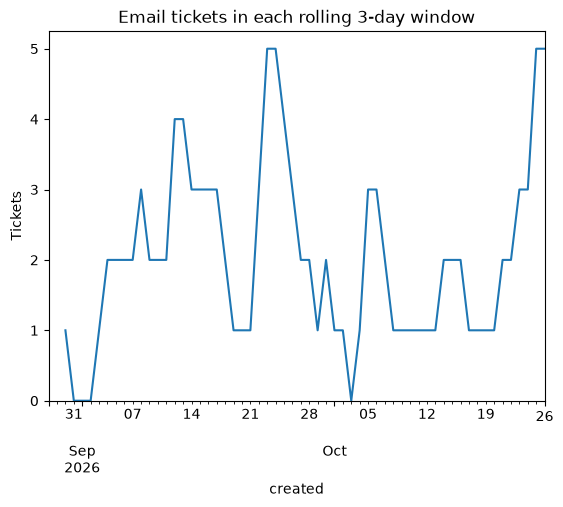

In [91]:
import matplotlib.pyplot as plt

rolling_email = daily_email.rolling(3).sum()

rolling_email.plot(title="Email tickets in each rolling 3-day window")
plt.ylabel("Tickets")
plt.ylim(bottom=0)
plt.show()

**Chart:** `.plot()` draws a line chart with dates along the bottom.
`plt.ylim(bottom=0)` starts the axis at zero so small changes don't look dramatic.
Email is a quiet channel (~1 ticket a day), with small peaks of 5 in late September
and late October.

## Using AI tools  (1:25:29)

**Exercise:** Ask Claude in VS Code to review one of your cells above. Note what it suggested, what you accepted, and why you rejected anything.

**What I learned:** 

In [92]:
vpn_network_high_over_4h = tickets[
    tickets["category"].isin(["VPN", "Wi-Fi / network"])
    & (tickets["priority"] == "High")
    & (tickets["resolution_hours"] > 4)
]

vpn_network_high_over_4h

,ticket_id,created,resolved,category,priority,status,assignee,channel,resolution_hours,age_hours,...,urgent,state,weekday,sla_hours_apply,sla_status,sla_hours,sla_breached,age_days,week,cumulative_hours
5,1006,2026-08-30 15:12:00,2026-08-30 22:05:00,Wi-Fi / network,High,Closed,Jordan,Portal,6.883333,NaN,...,Yes,Resolved,Sunday,4,Breached,4,True,NaN,2026-08-24/2026-08-30,206.65
196,1197,2026-10-15 10:01:00,2026-10-15 17:53:00,Wi-Fi / network,High,Closed,Sam,Portal,7.866667,NaN,...,Yes,Resolved,Thursday,4,Breached,4,True,NaN,2026-10-12/2026-10-18,6085.20


Here i used vs codes ai functionality ask " Use tickets dataframe to grab people resolution hours over 4 hours with vpn /network issues". This functionality allows me to write a complex query and receive my desired output.